<a href="https://colab.research.google.com/github/rperezen/intro-to-ML/blob/main/ml_hw_6_pt_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

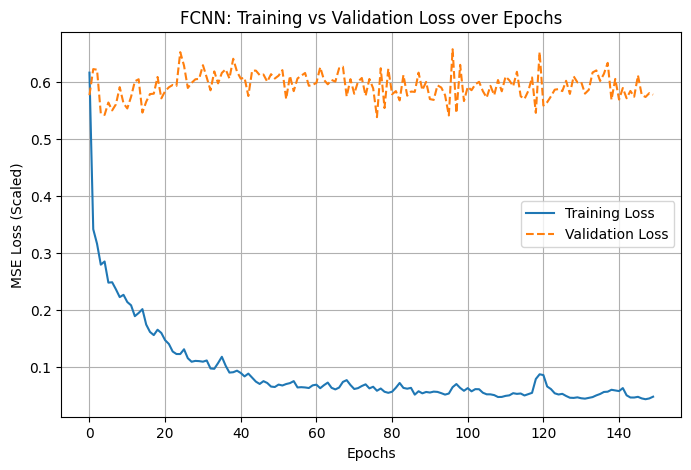


--- MODEL PERFORMANCE COMPARISON ---
1. Neural Network (FCNN):
   MSE:  1,781,021,540,352.00
   RMSE: 1,334,549.19
   R2:   0.6476

2. Linear Regression:
   MSE:  1,800,793,719,718.97
   RMSE: 1,341,936.56
   R2:   0.6437

3. Support Vector Regression (SVR):
   MSE:  2,988,215,173,645.57
   RMSE: 1,728,645.47
   R2:   0.4088


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score

# ==========================================
# 1. DATA PREPARATION & PREPROCESSING
# ==========================================
# Load dataset
df = pd.read_csv('Housing.csv')

# Map binary categorical variables to 1/0
binary_vars = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
for var in binary_vars:
    if var in df.columns:
        df[var] = df[var].apply(lambda x: 1 if str(x).lower() == 'yes' else (0 if str(x).lower() == 'no' else x))

features = ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom',
            'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea']
X = df[features].values
y = df['price'].values

# 80/20 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize inputs (Fit on train, transform on both to prevent data leakage)
scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

# Standardize target variable for stable Neural Network training
scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1)).flatten()
y_test_scaled = scaler_y.transform(y_test.reshape(-1, 1)).flatten()

# Convert to PyTorch Tensors
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train_scaled, dtype=torch.float32).view(-1, 1)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_t = torch.tensor(y_test_scaled, dtype=torch.float32).view(-1, 1)

# Create DataLoader for batching
train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=32, shuffle=True)

# ==========================================
# 2. NEURAL NETWORK DEVELOPMENT (1.a)
# ==========================================
class HousingFCNN(nn.Module):
    def __init__(self):
        super(HousingFCNN, self).__init__()
        # 11 features -> Hidden 1 (64 neurons) -> Hidden 2 (32 neurons) -> Output (1 price)
        self.fc1 = nn.Linear(11, 64)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(64, 32)
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(32, 1)

    def forward(self, x):
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        return self.fc3(x)

model = HousingFCNN()
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.005)

epochs = 150
train_losses, val_losses = [], []

# Training Loop
for epoch in range(1, epochs + 1):
    model.train()
    batch_losses = []

    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        preds = model(batch_X)
        loss = criterion(preds, batch_y)
        loss.backward()
        optimizer.step()
        batch_losses.append(loss.item())

    train_losses.append(np.mean(batch_losses))

    # Validation step
    model.eval()
    with torch.no_grad():
        val_preds = model(X_test_t)
        val_loss = criterion(val_preds, y_test_t)
        val_losses.append(val_loss.item())

# Evaluate Neural Network (Unscale predictions back to true dollar values)
model.eval()
with torch.no_grad():
    nn_preds_scaled = model(X_test_t).numpy()
    nn_preds = scaler_y.inverse_transform(nn_preds_scaled).flatten()

nn_mse = mean_squared_error(y_test, nn_preds)
nn_rmse = np.sqrt(nn_mse)
nn_r2 = r2_score(y_test, nn_preds)

# Plot Loss Curve
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss', linestyle='--')
plt.title('FCNN: Training vs Validation Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('MSE Loss (Scaled)')
plt.legend()
plt.grid(True)
plt.show()

# ==========================================
# 3. TRADITIONAL MACHINE LEARNING (1.b)
# ==========================================
# Linear Regression
lr = LinearRegression()
lr.fit(X_train_scaled, y_train) # Trained directly on unscaled Y for simplicity
lr_preds = lr.predict(X_test_scaled)

lr_mse = mean_squared_error(y_test, lr_preds)
lr_rmse = np.sqrt(lr_mse)
lr_r2 = r2_score(y_test, lr_preds)

# Support Vector Regression (SVR)
svr = SVR(kernel='rbf', C=100000, gamma='scale')
svr.fit(X_train_scaled, y_train)
svr_preds = svr.predict(X_test_scaled)

svr_mse = mean_squared_error(y_test, svr_preds)
svr_rmse = np.sqrt(svr_mse)
svr_r2 = r2_score(y_test, svr_preds)

# ==========================================
# 4. REPORT RESULTS
# ==========================================
print("\n--- MODEL PERFORMANCE COMPARISON ---")
print(f"1. Neural Network (FCNN):")
print(f"   MSE:  {nn_mse:,.2f}")
print(f"   RMSE: {nn_rmse:,.2f}")
print(f"   R2:   {nn_r2:.4f}")

print(f"\n2. Linear Regression:")
print(f"   MSE:  {lr_mse:,.2f}")
print(f"   RMSE: {lr_rmse:,.2f}")
print(f"   R2:   {lr_r2:.4f}")

print(f"\n3. Support Vector Regression (SVR):")
print(f"   MSE:  {svr_mse:,.2f}")
print(f"   RMSE: {svr_rmse:,.2f}")
print(f"   R2:   {svr_r2:.4f}")